# Selective JEV assistance under a strict inference budget

**Executed exploratory study of cached predictions; no new paid inference.**

The question is whether JEV improves detection of positive suicide-related texts
beyond threshold tuning and simple combination rules, and how many requests those
rules would need. Accuracy gains are decomposed into missed-positive recovery,
new misses, corrected false alarms, and new false alarms. Positive means the
dataset label `suicide=1`, not a clinical diagnosis.

The historical 5,000 texts were already inspected. A deterministic 2,000/3,000
development/evaluation partition supports honest *within-study* model fitting and
threshold selection; it does **not** turn the reused test set into independent
confirmation. All policies below are exploratory. Previous notebooks and result
directories are preserved.

### Research questions and how to read this notebook

1. **Reproduction:** Do the saved per-example records reproduce the historical
   accuracy gain, and how much of that gain comes from fewer missed positives
   rather than fewer false alarms?
2. **Sensitivity-controlled comparison:** At thresholds chosen for the same
   development recall target, does JEV reduce evaluation false alarms or increase
   precision relative to threshold-tuned XGBoost?
3. **Request efficiency:** Can a short-circuit rule retain useful corrections
   while requiring JEV for only a fraction of the historical routing population?
4. **Score quality:** Does development-only calibration improve held-out score
   losses, and does a two-model combiner add evidence beyond calibrated JEV alone?

These questions organize an exploratory reanalysis, not a prospectively
registered confirmatory trial. Neither small p-values nor a new partition name
remove the prior exposure of these texts. Both recall targets, the unsuccessful
or inconclusive alternatives, and the request trade-offs are reported together.

The notebook separates four evidence levels:

| Evidence level | What can be established here | What it cannot establish |
| --- | --- | --- |
| Saved provider outcomes | Historical statuses and exported risk scores for 5,000 selected cases | Independent authentication without the private ledger or raw provider payloads |
| Recalculated cached analysis | Metrics, transitions and alternative decisions on actual exported rows | New provider measurements or performance outside cache coverage |
| Aggregate-derived full-test results | Counts and additive losses when all unselected predictions are unchanged | Full-test rankings or globally retuned thresholds |
| Optional additional study | Tested sampling and two-phase budget-accounting software | New empirical outcomes while inference is disabled and source artifacts are missing |

Read the reproduction and evidence audit first, then the held-out policy and
matched-sensitivity comparisons. The calibration/routing analyses explain the
trade-offs; they do not override the population and independence limitations.

In [1]:
%matplotlib inline
from pathlib import Path
import json
import sys
import hashlib
import subprocess
import unittest.mock as mock
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'jev_research').is_dir() and (p / 'pyproject.toml').is_file())
sys.path.insert(0, str(ROOT))
from jev_research.budgeted_experiments import (
    run_cached_study, policy_output, metrics, digest, file_digest, save_json, save_table,
)
from jev_research.additional_experiment import write_pending_plan

RUN_NEW_JEV_INFERENCE = False
MAX_NEW_JEV_ATTEMPTS = 500
RANDOM_SEED = 42
AUTHORIZED_ADDITIONAL_MANIFEST_SHA256 = None
RESULTS = ROOT / 'research/results/jev_probability_hybrid_budgeted_experiments'
PRIVATE = ROOT / 'artifacts/jev_probability_hybrid_budgeted_experiments'
FIGURES = RESULTS / 'figures'
for directory in [RESULTS, PRIVATE, FIGURES]:
    directory.mkdir(parents=True, exist_ok=True)

# Defense in depth: the entire default notebook rejects HTTP requests.
# The separately documented, explicit paid runner is outside this offline notebook.
assert RUN_NEW_JEV_INFERENCE is False, 'Use the explicit two-phase runner for an authorized additional study.'
http_guard = mock.patch('requests.sessions.Session.request',
                        side_effect=RuntimeError('HTTP disabled in the default offline notebook'))
http_guard.start()
original_paths = [ROOT / 'assets/notebooks/jev_probability_hybrid_5000.ipynb',
                  *sorted((ROOT / 'research/results/jev_probability_hybrid').glob('*.json')),
                  ROOT / 'assets/notebooks/jev_xgboost_error_rescue.ipynb']
original_fingerprints = {str(p.relative_to(ROOT)): file_digest(p) for p in original_paths}
pd.set_option('display.max_columns', 30)
pd.set_option('display.max_colwidth', 85)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False})
print('Offline default: zero new paid attempts. Global optional allowance: 500, not activation.')
print('No models are retrained. No original study ledger is opened or changed.')

Offline default: zero new paid attempts. Global optional allowance: 500, not activation.
No models are retrained. No original study ledger is opened or changed.


## 1. Evidence audit and protocol

The reproducible primary evidence is the committed per-example prediction export
and routing manifest. They can be cross-checked against each other and the saved
report. The private SQLite ledger, raw provider payloads, original CSV, full
baseline prediction tables, and fitted Word2Vec/XGBoost models are absent. Public
exports cannot independently authenticate the underlying provider responses.

A version-14 Kaggle recovery attempt during repository inspection returned a
proxy **403 Forbidden for api.kaggle.com**. Native Git read access worked; the
tracked tree and available workspace contained no missing private artifacts.
This notebook performs no downloads and does not silently retrain a replacement
baseline. Full-population ranking metrics cannot be reconstructed from confusion
counts. Original dataset checksum and baseline fingerprint are retained below.

The source pipeline uses `non-suicide=0, suicide=1`, stratified 64/16/20 splits
(seed 42), raw normalized duplicate removal/conflict checks, then cleaning with
train → validation → test priority for cleaned collisions. Negations are expanded
before punctuation removal. Word2Vec vocabulary/vectors and XGBoost are fitted
on training rows only, according to source inspection. Without private tables we
cannot rerun the original raw/cleaned split-disjointness checks. Author and time
identifiers are not supplied; author/temporal leakage and author-level resampling
are unavailable.

Raw conflicting-label filtering uses labels across the dataset before splitting;
this is a global quality filter, not strictly train-only preprocessing. Learned
features still use training rows only. The risk-rating question and dataset's
binary text labels also need not represent the same clinical construct.

The fixed `jev-latest` question requests a numeric suicidal-intent **risk rating**
from 0 to 1. It is not verified token confidence or a calibrated probability.
The parser accepts finite numeric `answers.department.score` values in [0,1],
rejecting booleans. The client sends the original text without local truncation;
provider-side context limits are unknown. The alias has no immutable recorded
backend revision.

In [2]:
study = run_cached_study(ROOT, RESULTS)
audit, frozen, tables = study['audit'], study['frozen'], study['tables']
all_rows, development, evaluation = study['frame'], study['development'], study['evaluation']
specs, thresholds = frozen['specifications'], frozen['thresholds']
display(pd.DataFrame(audit['sources']))
display(pd.Series({k: audit[k] for k in [
    'source_revision', 'dataset_sha256', 'baseline_fingerprint', 'selected_n',
    'successes', 'failures', 'prior_error_study_overlap_n',
    'prior_overlap_different_scores_n', 'earlier_additional_compatible_cache_n',
    'request_model', 'historical_attempts', 'historical_phase_wall_seconds',
    'new_paid_attempts']}, name='Audit'))
display(Markdown('**Exact fixed scoring question:** ' + audit['question']['instructions']))
print('Historical request dates (UTC):', audit['historical_execution_window_utc'])
print(audit['cost_and_latency'])

,path,available,sha256,evidence
0,research/results/jev_probability_hybrid/predictions.json,True,9f04d56564020ee5f860528691c869d3fa273d0a481d4d163e08a4c53cfff042,committed public export
1,research/results/jev_probability_hybrid/routing_manifest.json,True,5c4738c3a0e8fcde034e1c104ccffc54d59b0711d3de1650ce91739c34ad408f,committed public export
2,research/results/jev_probability_hybrid/study.json,True,4e4ea91e98f318da48f458d8875f7548d5ff3d2f0a2785e0a8d5fd2f09ab6971,committed public export
3,research/results/jev_probability_hybrid/hybrid_report.json,True,05a2495ba8c7d7dcdb5f261cf68eb54f0041336af238d01051c173d66e77575a,committed public export
4,research/results/jev_probability_hybrid/execution_audit.json,True,0cad5d56c8cf033c611962df105956c1e51ec2c95eaaa2d6a01a9bf0f28bbc8f,committed public export
5,research/results/jev_probability_hybrid/inference_budget.json,True,25ba71253c70d0c94bccda14bcf5c7b49e2c571fb327e0f5cb5e3ad84ad62faf,committed public export
6,research/results/jev_probability_hybrid/validation_bins.json,True,4904f55acbd3141d191eec6a07bf6e05c68ecf240e4baa3f3ee9a533bff92b8f,committed public export
7,data/Suicide_Detection.csv,False,None,private artifact; availability checked in this checkout
8,artifacts/jev_probability_hybrid/cohort.csv.gz,False,None,private artifact; availability checked in this checkout
9,artifacts/jev_probability_hybrid/budget.sqlite3,False,None,private artifact; availability checked in this checkout


source_revision                                                  c70306c934a2c840d1fcd1d2378cbf241ed644b5
dataset_sha256                           1ec16b065a2fae36488de16e8abfc326586a576a25901e09467223e545ddd295
baseline_fingerprint                     b154407429c3f6d7dd39f87006eb4dd9305d283146ccf27546d57f0d27fa7fd2
selected_n                                                                                           5000
successes                                                                                            4996
failures                                                                                                4
prior_error_study_overlap_n                                                                            21
prior_overlap_different_scores_n                                                                       11
earlier_additional_compatible_cache_n                                                                  19
request_model                                 

**Exact fixed scoring question:** On a scale of 0 to 1, how likely is it that this text indicates a risk of suicidal intent?

Historical request dates (UTC): {'first_attempt': '2026-10-21T19:07:43.985618+00:00', 'last_finished': '2026-10-21T19:29:07.961259+00:00'}
No pricing, currency, usage, or per-request latency retained in public exports. Phase wall duration includes concurrent requests and is not mean latency.


There are **21** overlapping texts between the original error study and the
probability study; **11** have different JEV scores in the two saved runs. We
retain the probability-study response for every common-population comparison,
without cherry-picking the better run. This shows response variability; it does
not identify whether stochastic inference or a mutable backend caused it.
The 19 additional earlier responses come from a gold-label-selected error study;
pooling them would bias the present probability-selected population. They remain
available evidence and are excluded from future new-request sampling, along with
every previously selected sample. No historical failed request is resent.

## 2. Reproduce the previous result on identical examples

All four failed requests stay in the denominator and keep XGBoost's score and
decision. The following metrics and transitions are recomputed from the actual
5,000 prediction records and asserted against the saved report. OR predicts
positive when either model is positive; AND requires both positives. The 50:50
mean is a fixed score fusion. The last three policies are new **calculations
from historical responses**, not new provider measurements.

**Cost columns are prospective binary-decision request counts.** Historical
acquisition cost was 5,000 attempts for this cache (plus 40 in the earlier study).
Reading the cache now costs zero new requests. OR needs JEV only for eligible
XGB-negative cases; AND needs it only for eligible XGB-positive cases. A future
system that also wants both scores for every example would lose this saving.
Binary OR/AND have no claimed probability metrics in these tables.

### Decision rules, fallback and request accounting

For example $i$, let $x_i$ be its XGBoost score, $j_i$ its available JEV rating,
and $t$ a decision threshold. The original decision is
$b_i=\mathbb{1}[x_i\geq 0.50]$. On routed examples with successful JEV responses:

| Policy | Positive decision | When JEV is operationally needed |
| --- | --- | --- |
| XGBoost | $\mathbb{1}[x_i\geq t]$ | Never |
| Replacement | $\mathbb{1}[j_i\geq t]$ | Every routed example |
| OR | $\mathbb{1}[x_i\geq t\;\mathrm{or}\;j_i\geq t]$ | Only if $x_i<t$ |
| AND | $\mathbb{1}[x_i\geq t\;\mathrm{and}\;j_i\geq t]$ | Only if $x_i\geq t$ |
| Weighted mean | $\mathbb{1}[(1-\alpha)x_i+\alpha j_i\geq t]$ | Every routed example for $0<\alpha<1$ |

If a decision **requires** JEV and its result is failed, pending, or unavailable,
retain $b_i$; do not remove the example, fill in an invented JEV rating, or apply
a tuned cutoff to that fallback decision. A short-circuit decision needs no
fallback when XGBoost already determines the result. Unrouted examples also keep
$b_i$. These details matter when $t\ne0.50$.

For score diagnostics, an unavailable rating is represented by the original
XGBoost score. At a tuned threshold the operational hard fallback may therefore
differ from simply thresholding that diagnostic score. Operational confusion
counts always use the explicit fallback decisions. All 5,000 rows remain in
their population denominator.

The historical attempt count, prospective decision request count and new paid
attempt count answer different questions. In particular, a prospective count of
3,000 does **not** authorize 3,000 new calls: this study makes zero, and the
optional additional study has its own shared hard limit of 500 attempts.

In [3]:
historical = tables['historical_selected_comparison']
display(historical[['policy', 'n', 'accuracy', 'balanced_accuracy', 'precision', 'recall',
                    'specificity', 'f1', 'f2', 'macro_f1', 'fn', 'fp', 'prospective_requests']])
display(historical[['policy', 'corrected', 'introduced', 'net_correct',
                    'fn_recovered', 'fn_introduced', 'fp_corrected', 'fp_introduced',
                    'accuracy_change_pp', 'accuracy_relative_improvement_pct']])
replacement = historical.set_index('policy').loc['JEV replacement']
assert replacement.corrected - replacement.introduced == replacement.net_correct == 732
assert replacement.fn_recovered == 538 and replacement.fn_introduced == 511
assert replacement.fp_corrected == 801 and replacement.fp_introduced == 96
assert historical.set_index('policy').loc['OR', ['fn', 'fp']].tolist() == [322, 1049]
display(Markdown(
    f"Replacement improves selected accuracy by **{replacement.accuracy_change_pp:.2f} percentage points**, "
    f"a **{replacement.accuracy_relative_improvement_pct:.2f}% relative improvement**. "
    'These are different quantities. Only 27 of the 732 net additional correct predictions '
    'come from a net reduction in missed positives; 705 come from fewer false alarms.'
))

,policy,n,accuracy,balanced_accuracy,precision,recall,specificity,f1,f2,macro_f1,fn,fp,prospective_requests
0,XGB@0.50,5000,0.6374,0.632819,0.661577,0.684172,0.581467,0.672685,0.679530,0.633137,860,953,0
1,JEV replacement,5000,0.7838,0.792586,0.884004,0.694087,0.891085,0.777618,0.725249,0.783633,833,248,5000
2,OR,5000,0.7258,0.710527,0.695942,0.881748,0.539306,0.777904,0.837052,0.709830,322,1049,2184
3,AND,5000,0.6954,0.714878,0.898936,0.496511,0.933245,0.639697,0.545337,0.687941,1371,152,2816
4,Mean 50:50,5000,0.7958,0.803172,0.882988,0.720529,0.885815,0.793529,0.748056,0.795775,761,260,5000


,policy,corrected,introduced,net_correct,fn_recovered,fn_introduced,fp_corrected,fp_introduced,accuracy_change_pp,accuracy_relative_improvement_pct
0,XGB@0.50,0,0,0,0,0,0,0,0.00,0.000000
1,JEV replacement,1339,607,732,538,511,801,96,14.64,22.968309
2,OR,538,96,442,538,0,0,96,8.84,13.868842
3,AND,801,511,290,0,511,801,0,5.80,9.099467
4,Mean 50:50,1269,477,792,501,402,768,75,15.84,24.850957


Replacement improves selected accuracy by **14.64 percentage points**, a **22.97% relative improvement**. These are different quantities. Only 27 of the 732 net additional correct predictions come from a net reduction in missed positives; 705 come from fewer false alarms.

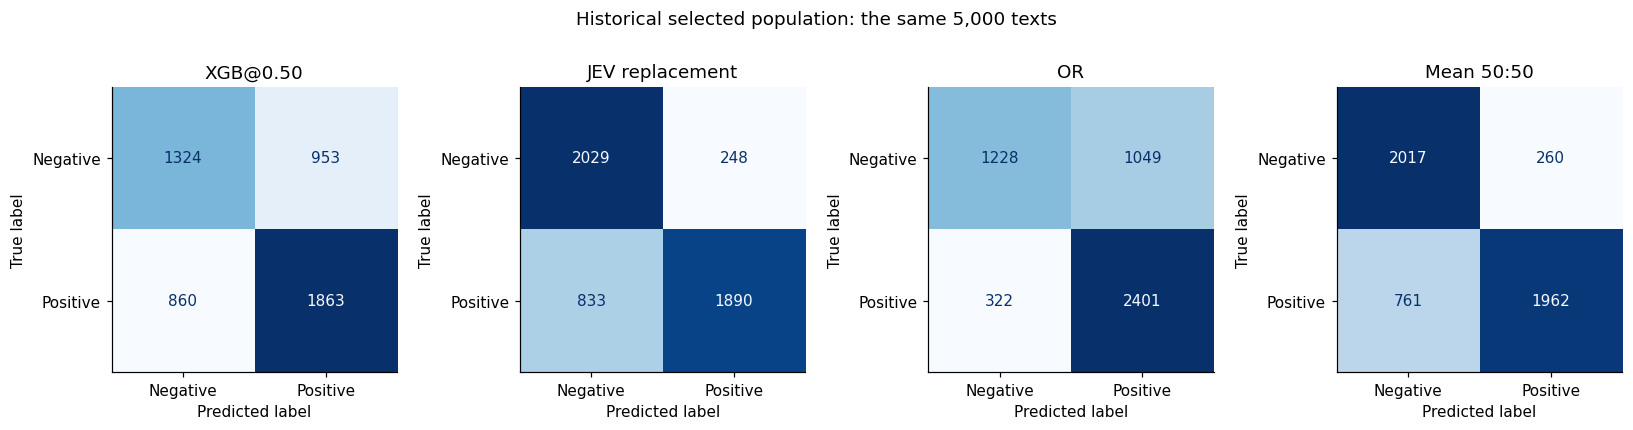

In [4]:
from sklearn.metrics import ConfusionMatrixDisplay
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
for ax, name in zip(axes, ['XGB@0.50', 'JEV replacement', 'OR', 'Mean 50:50']):
    row = historical.set_index('policy').loc[name]
    matrix = np.array([[row.tn, row.fp], [row.fn, row.tp]], dtype=int)
    ConfusionMatrixDisplay(matrix, display_labels=['Negative', 'Positive']).plot(
        ax=ax, colorbar=False, values_format='d', cmap='Blues')
    ax.set_title(name)
fig.suptitle('Historical selected population: the same 5,000 texts', y=1.04)
fig.tight_layout()
fig.savefig(FIGURES / 'historical_confusions.png', dpi=160, bbox_inches='tight')
plt.show()
plt.close(fig)

### Full-test quantities supported by aggregates

For fixed rules on the **exact same 5,000-row manifest**, unchanged out-of-cache
confusion counts can be added back to obtain population-level counts and rates.
The next table is **derived from public full-test baseline aggregates plus exact
selected-row changes**, not recomputed from 46,342 individual predictions. The
1,067 other eligible texts remain with XGBoost, as do all texts outside the
original interval. Do not interpret this as querying every eligible example.

Brier score and log loss are additive, so they can also be derived for score
policies with the same unchanged outside scores. Full-test ROC-AUC/AP and global
threshold retuning cannot be recovered this way. The saved full-test ROC-AUC
decreases from 0.975169 to 0.974644 and log loss increases from 0.201994 to
0.205766 for the original replacement rule; the AUC figures are report-only.

In [5]:
full_derived = tables['full_population_derived']
display(full_derived[['policy', 'n', 'accuracy', 'precision', 'recall', 'fn', 'fp',
                      'misses_per_1000', 'false_alarms_per_1000', 'prospective_requests',
                      'routing_fraction', 'accuracy_change_pp',
                      'accuracy_relative_improvement_pct', 'brier', 'log_loss']])
assert full_derived.roc_auc.isna().all()
assert full_derived.set_index('policy').loc['JEV replacement', ['fn', 'fp']].tolist() == [1808, 1182]
print('All rows outside the historical manifest remain unchanged. No full-test scores fabricated.')

,policy,n,accuracy,precision,recall,fn,fp,misses_per_1000,false_alarms_per_1000,prospective_requests,routing_fraction,accuracy_change_pp,accuracy_relative_improvement_pct,brier,log_loss
0,XGB@0.50,46342,0.919684,0.918835,0.920895,1835,1887,39.596910,40.719002,0,0.000000,0.000000,0.000000,0.059086,0.201994
1,JEV replacement,46342,0.935480,0.947632,0.922059,1808,1182,39.014285,25.506020,5000,0.107893,1.579561,1.717504,0.052802,0.205766
2,OR,46342,0.929222,0.916970,0.944088,1297,1983,27.987571,42.790557,2184,0.047128,0.953778,1.037072,NaN,NaN
3,AND,46342,0.925942,0.950495,0.898866,2346,1086,50.623624,23.434465,2816,0.060766,0.625782,0.680432,NaN,NaN
4,Mean 50:50,46342,0.936774,0.947296,0.925163,1736,1194,37.460619,25.764965,5000,0.107893,1.709033,1.858282,0.051417,0.184645


All rows outside the historical manifest remain unchanged. No full-test scores fabricated.


## 3. Development/evaluation separation and frozen policies

Sort by SHA-256 of seed 42, a fixed study tag, and stable sample ID; assign the
first 2,000 to development and the remaining 3,000 to evaluation. Labels,
correctness and JEV scores do not enter partition assignment. IDs, row IDs and
raw-text hashes are checked for disjointness. This does not verify semantic,
author or temporal independence.

The following choices use **development only**:

- XGBoost thresholds maximizing F1 and F2, with fixed precision/proximity/tie rules.
- A JEV-weight choice from {0.25, 0.50, 0.75}, minimizing development log loss.
- Sigmoid recalibration of clipped score logits, separately for XGB and JEV.
- A two-feature logistic combiner of the clipped XGB/JEV logits, fixed L2 C=1.

No paid hyperparameter search is used. JEV calibrators/fusion fit successful
development responses only. Every missing evaluation response keeps XGB@0.50,
including in target-recall experiments. XGB-only policies use their selected
thresholds. Unrouted examples also keep XGB@0.50. Threshold candidate values
come only from development scores; evaluation labels cannot select a threshold.
Calibration is conditional on this restricted score-range population.

### Metric definitions and selection objectives

With positive-class counts TP, FN and negative-class counts TN, FP:

\[
\mathrm{recall}=\frac{TP}{TP+FN},\quad
\mathrm{precision}=\frac{TP}{TP+FP},\quad
\mathrm{specificity}=\frac{TN}{TN+FP},\quad
\mathrm{accuracy}=\frac{TP+TN}{N}.
\]

Balanced accuracy is the mean of recall and specificity. Positive-class F1 is
$2TP/(2TP+FP+FN)$, while F2 is $5TP/(5TP+4FN+FP)$ and therefore gives missed
positives greater weight. Macro F1 averages the two class-specific F1 scores.
Misses and false alarms per 1,000 texts are $1000FN/N$ and $1000FP/N$; the
denominator must always be identified as the selected subset or the supported
full population.

The F1/F2 XGB baselines maximize their respective development objectives. For
target recall $r\in\{0.90,0.95\}$, select a development threshold minimizing FP
subject to recall $\geq r$, with the documented deterministic tie rules. An F2
optimum is not required to satisfy a particular sensitivity target, and a target
met on development may be missed on evaluation. No evaluation-label threshold
adjustment is allowed.

Accuracy changes are reported as both percentage points and relative changes:
$100(A_{new}-A_{base})$ versus
$100(A_{new}-A_{base})/A_{base}$. Relative error reduction would be a third,
different quantity and is not substituted for either one.

ROC-AUC measures score ranking across positive/negative examples; average
precision summarizes the precision-recall staircase. Neither is determined by a
single confusion matrix. Brier score and log loss are defined below and penalize
score quality rather than only thresholded decisions. They are diagnostics here,
not proof that raw JEV ratings are calibrated event probabilities.

In [6]:
display(all_rows.groupby('partition').agg(n=('sample_id', 'size'),
        positives=('y_true', 'sum'), successes=('jev_status', lambda x: int(x.eq('succeeded').sum()))))
assert len(development) == 2000 and len(evaluation) == 3000
for column in ['sample_id', 'row_id', 'text_sha256']:
    assert not set(development[column]) & set(evaluation[column])
display(pd.DataFrame([{'policy': name, 'threshold': thresholds[name], **spec}
                      for name, spec in specs.items()]))
display(pd.DataFrame(frozen['selection']['weight_trials']))
print('Frozen policy digest:', digest(frozen))
print('Evaluation remains exploratory despite this disjoint fitting partition.')

,n,positives,successes
partition,,,
development,2000,1107,1999
evaluation,3000,1616,2997


,policy,threshold,kind,jev_weight,coefficients,intercept,C,development_training_n
0,XGB@0.50,0.500000,xgb,NaN,NaN,NaN,NaN,NaN
1,JEV replacement,0.500000,replacement,NaN,NaN,NaN,NaN,NaN
2,OR,0.500000,or,NaN,NaN,NaN,NaN,NaN
3,AND,0.500000,and,NaN,NaN,NaN,NaN,NaN
4,Mean 50:50,0.500000,weighted,0.50,NaN,NaN,NaN,NaN
5,Weighted (dev),0.500000,weighted,0.75,NaN,NaN,NaN,NaN
6,XGB sigmoid,0.500000,xgb_sigmoid,NaN,[0.9513019766321896],0.085771,1.0,2000.0
7,JEV sigmoid,0.500000,jev_sigmoid,NaN,[0.46207114441040137],0.705259,1.0,1999.0
8,Logistic fusion,0.500000,logistic,NaN,"[0.5364853957752261, 0.44117704146671893]",0.603296,1.0,1999.0
9,XGB threshold (dev F2),0.252898,xgb,NaN,NaN,NaN,NaN,NaN


,jev_weight,development_log_loss
0,0.25,0.532395
1,0.50,0.471702
2,0.75,0.451982


Frozen policy digest: 420b6425d89cde4a5e6c9f62163df01da8394ba306bb237965fcb1394d331222
Evaluation remains exploratory despite this disjoint fitting partition.


## 4. Policy comparison on the common exploratory evaluation population

These 3,000 examples were not used in the new fits/threshold choices. All
operational metrics include the historical failures. The F2-selected baseline
may select an almost-always-positive rule on this difficult score-range subset;
it is retained honestly. F1 and target-recall baselines provide additional
comparisons. Threshold and calibration changes do not incur provider requests.

In [7]:
comparison = tables['evaluation_comparison']
display(comparison[['policy', 'threshold', 'accuracy', 'balanced_accuracy', 'precision',
                    'recall', 'specificity', 'f1', 'f2', 'macro_f1', 'fn', 'fp',
                    'prospective_requests', 'required_unavailable_fallbacks']])
display(comparison[['policy', 'roc_auc', 'average_precision', 'brier', 'log_loss']])
display(comparison[['policy', 'fn_recovered', 'fn_introduced', 'fp_corrected',
                    'fp_introduced', 'net_correct', 'routing_fraction']])
print('Historical full cache: 5,000 attempts. New paid attempts for every policy above: 0.')

,policy,threshold,accuracy,balanced_accuracy,precision,recall,specificity,f1,f2,macro_f1,fn,fp,prospective_requests,required_unavailable_fallbacks
0,XGB@0.50,0.500000,0.629667,0.625442,0.649144,0.680074,0.570809,0.664249,0.673655,0.625696,517,594,0,0
1,JEV replacement,0.500000,0.777667,0.785950,0.881124,0.678837,0.893064,0.766865,0.711506,0.777188,519,148,3000,3
2,OR,0.500000,0.714667,0.701488,0.684645,0.871906,0.531069,0.767011,0.826684,0.699499,207,649,1307,1
3,AND,0.500000,0.692667,0.709904,0.894318,0.487005,0.932803,0.630609,0.535812,0.683741,829,93,1693,2
4,Mean 50:50,0.500000,0.788333,0.795540,0.880528,0.702351,0.888728,0.781411,0.731975,0.788121,481,154,3000,3
5,Weighted (dev),0.500000,0.781333,0.789457,0.883387,0.684406,0.894509,0.771269,0.716693,0.780909,510,146,3000,3
6,XGB sigmoid,0.500000,0.631667,0.625172,0.643459,0.709158,0.541185,0.674713,0.694967,0.625101,470,635,0,0
7,JEV sigmoid,0.500000,0.811000,0.810874,0.832594,0.812500,0.809249,0.822424,0.816441,0.810215,303,264,3000,3
8,Logistic fusion,0.500000,0.817000,0.816495,0.834903,0.823020,0.809971,0.828919,0.825369,0.816107,286,263,3000,3
9,XGB threshold (dev F2),0.252898,0.541000,0.502892,0.540114,0.995668,0.010116,0.700326,0.851954,0.360128,7,1370,0,0


,policy,roc_auc,average_precision,brier,log_loss
0,XGB@0.50,0.682157,0.704958,0.224318,0.639827
1,JEV replacement,0.891051,0.890143,0.167627,0.652517
2,OR,NaN,NaN,NaN,NaN
3,AND,NaN,NaN,NaN,NaN
4,Mean 50:50,0.871239,0.881570,0.153805,0.480167
5,Weighted (dev),0.884814,0.890134,0.150174,0.462948
6,XGB sigmoid,0.682157,0.704958,0.224390,0.639965
7,JEV sigmoid,0.891240,0.890291,0.132952,0.418894
8,Logistic fusion,0.893028,0.894425,0.131081,0.414240
9,XGB threshold (dev F2),0.682157,0.704958,0.224318,0.639827


,policy,fn_recovered,fn_introduced,fp_corrected,fp_introduced,net_correct,routing_fraction
0,XGB@0.50,0,0,0,0,0,0.000000
1,JEV replacement,310,312,501,55,444,1.000000
2,OR,310,0,0,55,255,0.435667
3,AND,0,312,501,0,189,0.564333
4,Mean 50:50,287,251,483,43,476,1.000000
5,Weighted (dev),301,294,498,50,455,1.000000
6,XGB sigmoid,47,0,0,41,6,0.000000
7,JEV sigmoid,390,176,448,118,544,1.000000
8,Logistic fusion,342,111,410,79,562,1.000000
9,XGB threshold (dev F2),510,0,0,776,-266,0.000000


Historical full cache: 5,000 attempts. New paid attempts for every policy above: 0.


## 5. Compare sensitivity using development targets of 0.90 and 0.95

For each score rule select the development threshold with the fewest false
alarms subject to the recall target; deterministic ties favor precision and the
higher cutoff. Exact >= ties are respected. A target that cannot be reached
would be marked unachievable. No threshold is moved after seeing evaluation.

**Equal development targets do not guarantee equal evaluation recall.** Compare
achieved recall and its paired difference, not just the target name. These
targets refer to the selected-population development subset; they are not a
claim of full-population 90%/95% sensitivity. Sigmoid XGB recalibration preserves
ranking and therefore cannot improve the attainable threshold trade-off here.
OR/AND short-circuit request counts depend on the chosen cutoff. AND at a very
low threshold can require JEV for almost every cached example, losing the
request saving it has at 0.50.

,policy,target,threshold,development_recall,development_precision,recall,precision,specificity,fn,fp,prospective_requests
0,XGB threshold (target),0.90,0.342598,0.900632,0.603511,0.887995,0.586912,0.270231,181,1010,0
1,JEV replacement,0.90,0.080000,0.908762,0.775636,0.887995,0.777778,0.703757,181,410,3000
2,OR,0.90,0.490000,0.900632,0.704594,0.880569,0.680536,0.517341,193,668,1259
3,AND,0.90,0.080000,0.908762,0.775636,0.887995,0.777778,0.703757,181,410,3000
4,Mean 50:50,0.90,0.328335,0.900632,0.758752,0.873762,0.751064,0.661850,204,468,3000
5,Weighted (dev),0.90,0.206365,0.904246,0.793814,0.886139,0.793352,0.730491,184,373,3000
6,XGB sigmoid,0.90,0.369531,0.900632,0.603511,0.887995,0.586912,0.270231,181,1010,0
7,JEV sigmoid,0.90,0.395732,0.908762,0.775636,0.887995,0.777778,0.703757,181,410,3000
8,Logistic fusion,0.90,0.418222,0.900632,0.800161,0.875619,0.797183,0.739884,201,360,3000
9,XGB threshold (target),0.95,0.293316,0.950316,0.576123,0.954208,0.563803,0.138006,74,1193,0


,policy,development_target_recall,delta_recall,delta_recall_ci_low,delta_recall_ci_high,delta_precision,delta_precision_ci_low,delta_precision_ci_high,net_fp_reduction,mcnemar_sensitivity_p
0,JEV replacement,0.90,0.000000,-0.020484,0.020837,0.190866,0.173847,0.208034,600,1.000000
1,OR,0.90,-0.007426,-0.024097,0.010027,0.093624,0.082907,0.105078,342,0.439033
6,Logistic fusion,0.90,-0.012376,-0.031427,0.006825,0.210271,0.193550,0.226623,650,0.236794
7,JEV replacement,0.95,0.006188,-0.007985,0.019351,0.149105,0.135779,0.162399,568,0.430021
8,OR,0.95,-0.018564,-0.031618,-0.006382,0.054602,0.046480,0.062801,260,0.004233
13,Logistic fusion,0.95,-0.015470,-0.029539,-0.001222,0.159957,0.146404,0.173423,614,0.038472


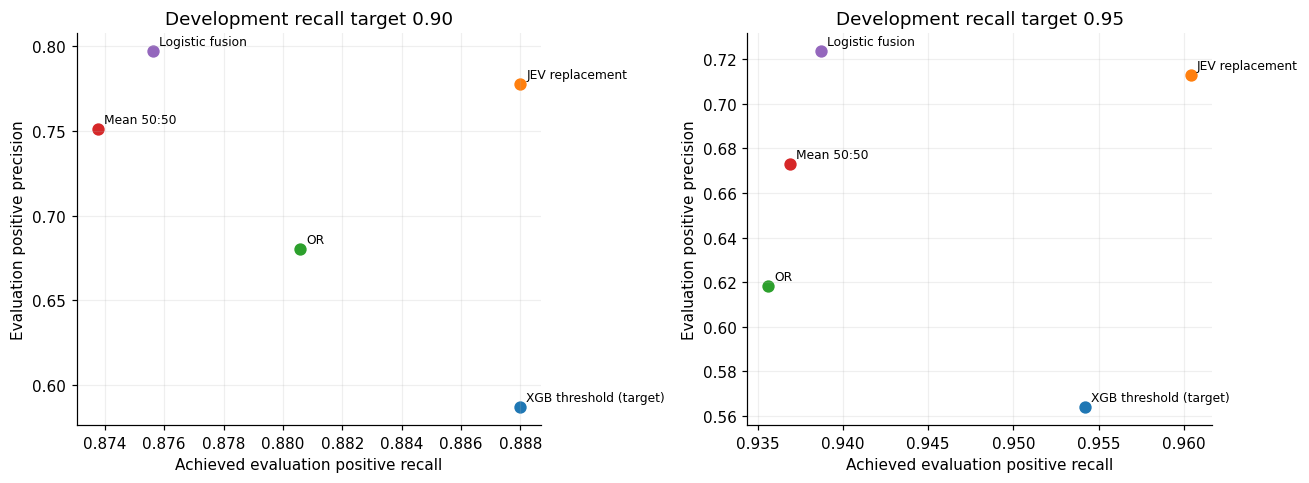

In [8]:
matched = tables['matched_recall_evaluation']
display(matched[['policy', 'target', 'threshold', 'development_recall', 'development_precision',
                 'recall', 'precision', 'specificity', 'fn', 'fp', 'prospective_requests']])
matched_ci = tables['matched_recall_uncertainty']
display(matched_ci.loc[matched_ci.policy.isin(['JEV replacement', 'OR', 'Logistic fusion']),
    ['policy', 'development_target_recall', 'delta_recall', 'delta_recall_ci_low',
     'delta_recall_ci_high', 'delta_precision', 'delta_precision_ci_low',
     'delta_precision_ci_high', 'net_fp_reduction', 'mcnemar_sensitivity_p']])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
names = ['XGB threshold (target)', 'JEV replacement', 'OR', 'Mean 50:50', 'Logistic fusion']
for ax, target in zip(axes, [.90, .95]):
    rows = matched.loc[matched.target.eq(target)].set_index('policy').loc[names]
    for name, row in rows.iterrows():
        ax.scatter(row.recall, row.precision, s=50)
        ax.annotate(name, (row.recall, row.precision), xytext=(4, 4), textcoords='offset points', fontsize=8)
    ax.set(xlabel='Achieved evaluation positive recall', ylabel='Evaluation positive precision',
           title=f'Development recall target {target:.2f}')
    ax.grid(alpha=.2)
fig.tight_layout()
fig.savefig(FIGURES / 'matched_sensitivity.png', dpi=170, bbox_inches='tight')
plt.show()
plt.close(fig)

## 6. Routing where JEV adds value, not just where XGB errs

The small analysis-prespecified interval set is the original [0.25,0.80), a
narrow [0.40,0.60), a below-threshold [0.25,0.50), and an above-threshold
[0.50,0.80) interval. Each is combined with replacement, OR, or a fixed mean;
XGB-only is also a candidate. These rules use actual cached responses inside
their interval and XGB fallback everywhere else. They never extrapolate JEV
predictions to the unqueried 1,067 eligible texts or outside original coverage.

Select a rule on development for each hypothetical FN:FP loss ratio 1, 5, and
10; ties favor fewer requests. These are sensitivity-analysis scenarios, not
clinical utilities or currency costs. Evaluation rows for all candidates are
descriptive; the selected-rule table is keyed only to development decisions.
The 0.05-wide bins below are descriptive and are not used to optimize an
elaborate sparse-bin policy.

For a hypothetical false-negative cost multiplier $c$, development selection
minimizes $L_c=c\,FN+FP$. Dividing by the common population size gives loss per
text. This multiplier expresses a scenario about the *relative* consequences of
the two error types; it is neither provider pricing nor an independently
validated clinical preference.

Net additional correct predictions per required request are
$(\mathrm{corrected}-\mathrm{introduced})/N_{requests}$. A region with a high
baseline error rate can still have poor JEV value if corrections are offset by
regressions. This quantity is descriptive for the observed routing population;
it does not estimate the unobserved benefit of requests outside cached coverage.
When no JEV requests are required, this ratio is undefined rather than an
infinite return on investment.

,policy,baseline_error_rate,corrected,introduced,net_fn_reduction,net_fp_reduction,prospective_requests,net_correct_per_request,loss_fn_cost_1,loss_fn_cost_5,loss_fn_cost_10
0,No JEV,0.351,0,0,0,0,0,NaN,0.3510,1.0370,1.8945
1,original/replacement,0.351,528,240,29,259,2000,0.144000,0.2070,0.8350,1.6200
2,original/or,0.351,228,41,228,-41,877,0.213227,0.2575,0.4875,0.7750
3,original/weighted,0.351,499,183,63,253,2000,0.158000,0.1930,0.7530,1.4530
4,narrow/replacement,0.351,226,72,56,98,649,0.237288,0.2740,0.8480,1.5655
5,narrow/or,0.351,112,16,112,-16,327,0.293578,0.3030,0.7650,1.3425
6,narrow/weighted,0.351,224,63,62,99,649,0.248074,0.2705,0.8325,1.5350
7,below/replacement,0.351,228,41,228,-41,877,0.213227,0.2575,0.4875,0.7750
8,below/or,0.351,228,41,228,-41,877,0.213227,0.2575,0.4875,0.7750
9,below/weighted,0.351,214,32,214,-32,877,0.207526,0.2600,0.5180,0.8405


,fn_to_fp_cost_ratio,policy,recall,precision,fn,fp,prospective_requests,net_correct_per_request
0,1,original/weighted,0.702351,0.880528,481,154,3000,0.158667
1,5,below/or,0.871906,0.684645,207,649,1307,0.195103
2,10,below/or,0.871906,0.684645,207,649,1307,0.195103


,partition,lower,upper,n,baseline_errors,baseline_error_rate,corrected,introduced,net_correct,fn_recovered,fn_introduced,fp_corrected,fp_introduced,net_fn_reduction,net_fp_reduction,accuracy_change_pp,accuracy_relative_improvement_pct,mcnemar_accuracy_p,mcnemar_sensitivity_p,successful_responses,net_correct_per_request
0,development,0.25,0.30,199,63,0.316583,43,5,38,43,0,0,5,43,-5,19.095477,27.941176,1.368048e-08,2.273737e-13,199,0.190955
1,development,0.30,0.35,166,55,0.331325,31,10,21,31,0,0,10,31,-10,12.650602,18.918919,1.450491e-03,9.313226e-10,166,0.126506
2,development,0.35,0.40,185,68,0.367568,42,10,32,42,0,0,10,42,-10,17.297297,27.350427,9.063272e-06,4.547474e-13,185,0.172973
3,development,0.40,0.45,157,73,0.464968,45,5,40,45,0,0,5,45,-5,25.477707,47.619048,4.209852e-09,5.684342e-14,157,0.254777
4,development,0.45,0.50,170,84,0.494118,67,11,56,67,0,0,11,67,-11,32.941176,65.116279,6.118310e-11,1.355253e-20,170,0.329412
5,development,0.50,0.55,150,65,0.433333,55,26,29,0,26,55,0,-26,55,19.333333,34.117647,1.688638e-03,2.980232e-08,150,0.193333
6,development,0.55,0.60,172,68,0.395349,59,30,29,0,30,59,0,-30,59,16.860465,27.884615,2.785269e-03,1.862645e-09,171,0.168605
7,development,0.60,0.65,163,58,0.355828,51,22,29,0,22,51,0,-22,51,17.791411,27.619048,9.142746e-04,4.768372e-07,163,0.177914
8,development,0.65,0.70,169,52,0.307692,44,35,9,0,35,44,0,-35,44,5.325444,7.692308,3.681876e-01,5.820766e-11,169,0.053254
9,development,0.70,0.75,198,58,0.292929,45,37,8,0,37,45,0,-37,45,4.040404,5.714286,4.397054e-01,1.455192e-11,198,0.040404


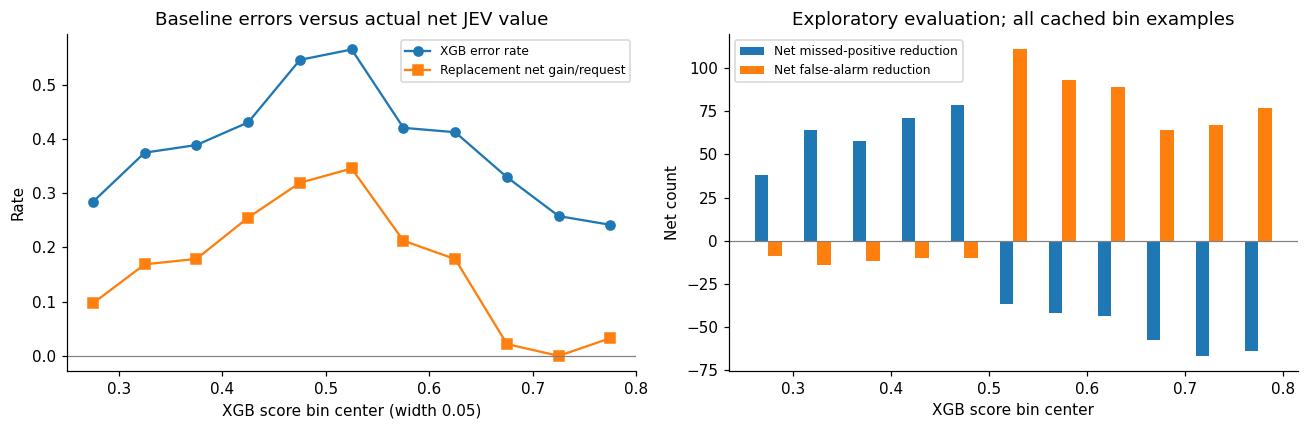

In [9]:
display(tables['routing_development'][['policy', 'baseline_error_rate', 'corrected', 'introduced',
        'net_fn_reduction', 'net_fp_reduction', 'prospective_requests', 'net_correct_per_request',
        'loss_fn_cost_1', 'loss_fn_cost_5', 'loss_fn_cost_10']])
display(tables['routing_selected_evaluation'][['fn_to_fp_cost_ratio', 'policy',
        'recall', 'precision', 'fn', 'fp', 'prospective_requests', 'net_correct_per_request']])
display(tables['score_bins_descriptive'])

bins = tables['score_bins_descriptive'].query("partition == 'evaluation'")
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
centers = (bins.lower + bins.upper)/2
axes[0].plot(centers, bins.baseline_error_rate, marker='o', label='XGB error rate')
axes[0].plot(centers, bins.net_correct_per_request, marker='s', label='Replacement net gain/request')
axes[0].axhline(0, color='gray', lw=.8)
axes[0].set(xlabel='XGB score bin center (width 0.05)', ylabel='Rate', title='Baseline errors versus actual net JEV value')
axes[0].legend(fontsize=8)
axes[1].bar(centers-.007, bins.net_fn_reduction, width=.014, label='Net missed-positive reduction')
axes[1].bar(centers+.007, bins.net_fp_reduction, width=.014, label='Net false-alarm reduction')
axes[1].axhline(0, color='gray', lw=.8)
axes[1].set(xlabel='XGB score bin center', ylabel='Net count', title='Exploratory evaluation; all cached bin examples')
axes[1].legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES / 'routing_value.png', dpi=170)
plt.show()
plt.close(fig)

## 7. Calibration, simple fusion and ranking boundaries

Reliability diagrams use ten fixed equal-width bins on evaluation only; sparse
bins are shown rather than merged after inspecting outcomes. Brier/log loss are
score-quality diagnostics conditional on coverage, not clinical calibration.
The original raw JEV replacement can improve accuracy while worsening log loss,
because confident mistakes are heavily penalized. Sigmoid calibration and
regularized fusion must earn any gains on the held-out analysis partition.

The boundary diagnostic examines actually observed adjacent 0.05-wide score
bands. We count cross-band ranking inversions after replacing one side's scores.
At the *original* 0.25/0.80 routing boundaries the other side is unobserved, so
inversion rates there are **not estimable**. At 0.40/0.60 both sides exist in the
cache, allowing local diagnostics for the narrower candidate. Such diagnostics
do not recover full-test AUC or prove that calibration fixes every ranking change.

### What is fitted, and what is measured?

For a bounded score $s$, define
$z(s)=\log(\tilde{s}/(1-\tilde{s}))$ with
$\tilde{s}=\mathrm{clip}(s,10^{-6},1-10^{-6})$, and
$\sigma(v)=1/(1+e^{-v})$. The fitted sigmoid is
$q=\sigma(a\,z(s)+b)$; the two-model fusion is
$q=\sigma(w_xz(x)+w_jz(j)+b)$. Coefficients and intercepts are learned on
development labels only using logistic regression with fixed L2 regularization
(`C=1`, inverse regularization strength). The coefficient table and frozen JSON
record the actual fitted parameters. There is no evaluation-driven search for C,
new prompt, or model family.

For diagnostic scores $q_i$ and labels $y_i$, lower values are better for

\[
\mathrm{Brier}=\frac{1}{N}\sum_i(q_i-y_i)^2,\qquad
\mathrm{LogLoss}=-\frac{1}{N}\sum_i\left[y_i\log q_i+(1-y_i)\log(1-q_i)\right].
\]

Log loss clips exact zero/one scores at floating-point machine precision when
evaluating, as in scikit-learn. This is distinct from the $10^{-6}$ clipping
used to construct finite model features. Raw JEV confidence-like extremes can
therefore incur a large log-loss penalty when wrong. A lower fitted loss on
development is not evidence of better calibration; the evaluation losses,
paired intervals and reliability diagram provide the relevant checks here.

A selected raw JEV threshold such as 0.03 is an empirical cutoff for this
restricted dataset and prompt. It must not be read as a calibrated 3% clinical
risk or a recommended intervention threshold. Separately calibrated scores may
have different numerical cutoffs while yielding the same ranking/decisions.

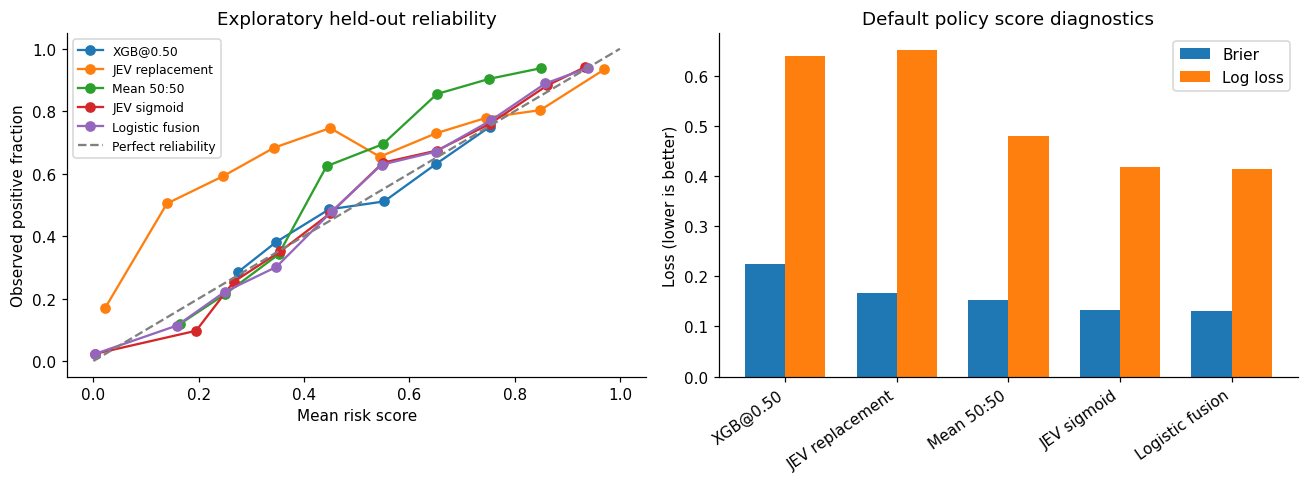

,policy,reference,loss,difference,ci_low,ci_high,replicates
0,JEV replacement,XGB@0.50,brier,-0.056691,-0.067661,-0.045241,2000
1,JEV replacement,XGB@0.50,log_loss,0.012691,-0.059365,0.097765,2000
2,JEV sigmoid,JEV replacement,brier,-0.034674,-0.040924,-0.028737,2000
3,JEV sigmoid,JEV replacement,log_loss,-0.233623,-0.302181,-0.175834,2000
4,XGB sigmoid,XGB@0.50,brier,0.000072,-0.000583,0.000762,2000
5,XGB sigmoid,XGB@0.50,log_loss,0.000138,-0.001283,0.001642,2000
6,Logistic fusion,XGB@0.50,brier,-0.093236,-0.100047,-0.086192,2000
7,Logistic fusion,XGB@0.50,log_loss,-0.225587,-0.244158,-0.204435,2000
8,Logistic fusion,JEV sigmoid,brier,-0.001871,-0.003828,0.000144,2000
9,Logistic fusion,JEV sigmoid,log_loss,-0.004654,-0.009514,0.000304,2000


Sigmoid JEV log loss is **0.4189**, versus **0.6525** before calibration. Adding XGB through logistic fusion gives only a **-0.0047** log-loss difference relative to calibrated JEV (paired 95% CI **-0.0095 to +0.0003**). That interval includes zero: the incremental fusion gain is inconclusive. XGB-only sigmoid calibration also shows no clear proper-score improvement.

,boundary,diagnostic,left_n,right_n,pairs,inversion_fraction,tied_pairs,local_auc,scope
0,0.25,baseline,0,299,0,NaN,0,0.499505,cached rows only; missing outer-boundary pairs are not estimable
1,0.25,replacement below boundary,0,299,0,NaN,0,0.499505,cached rows only; missing outer-boundary pairs are not estimable
2,0.25,replacement above boundary,0,299,0,NaN,0,0.887301,cached rows only; missing outer-boundary pairs are not estimable
3,0.40,baseline,257,239,61423,0.000000,0,0.523159,cached rows only; missing outer-boundary pairs are not estimable
4,0.40,replacement below boundary,257,239,61423,0.280416,0,0.740034,cached rows only; missing outer-boundary pairs are not estimable
5,0.40,replacement above boundary,257,239,61423,0.642495,0,0.745196,cached rows only; missing outer-boundary pairs are not estimable
6,0.50,baseline,216,214,46224,0.000000,0,0.449663,cached rows only; missing outer-boundary pairs are not estimable
7,0.50,replacement below boundary,216,214,46224,0.395271,0,0.734716,cached rows only; missing outer-boundary pairs are not estimable
8,0.50,replacement above boundary,216,214,46224,0.686418,0,0.734446,cached rows only; missing outer-boundary pairs are not estimable
9,0.60,baseline,240,252,60480,0.000000,0,0.508677,cached rows only; missing outer-boundary pairs are not estimable


In [10]:
reliability = tables['reliability']
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for name in ['XGB@0.50', 'JEV replacement', 'Mean 50:50', 'JEV sigmoid', 'Logistic fusion']:
    rows = reliability.loc[reliability.policy.eq(name)]
    axes[0].plot(rows.mean_score, rows.observed_positive_fraction, marker='o', label=name)
axes[0].plot([0, 1], [0, 1], '--', color='gray', label='Perfect reliability')
axes[0].set(xlabel='Mean risk score', ylabel='Observed positive fraction', title='Exploratory held-out reliability')
axes[0].legend(fontsize=8)
score_names = ['XGB@0.50', 'JEV replacement', 'Mean 50:50', 'JEV sigmoid', 'Logistic fusion']
score_rows = comparison.set_index('policy').loc[score_names]
positions = np.arange(len(score_names))
axes[1].bar(positions-.18, score_rows.brier, width=.36, label='Brier')
axes[1].bar(positions+.18, score_rows.log_loss, width=.36, label='Log loss')
axes[1].set_xticks(positions, score_names, rotation=35, ha='right')
axes[1].set(ylabel='Loss (lower is better)', title='Default policy score diagnostics')
axes[1].legend()
fig.tight_layout()
fig.savefig(FIGURES / 'calibration.png', dpi=170)
plt.show()
plt.close(fig)
display(tables['score_loss_uncertainty'])
loss_ci = tables['score_loss_uncertainty']
fusion_ci = loss_ci.loc[loss_ci.policy.eq('Logistic fusion') &
                       loss_ci.reference.eq('JEV sigmoid') & loss_ci.loss.eq('log_loss')].iloc[0]
display(Markdown(
    f"Sigmoid JEV log loss is **{comparison.set_index('policy').loc['JEV sigmoid', 'log_loss']:.4f}**, "
    f"versus **{comparison.set_index('policy').loc['JEV replacement', 'log_loss']:.4f}** before calibration. "
    f"Adding XGB through logistic fusion gives only a **{fusion_ci.difference:+.4f}** log-loss difference "
    f"relative to calibrated JEV (paired 95% CI **{fusion_ci.ci_low:+.4f} to {fusion_ci.ci_high:+.4f}**). "
    'That interval includes zero: the incremental fusion gain is inconclusive. '
    'XGB-only sigmoid calibration also shows no clear proper-score improvement.'
))
display(tables['boundary_ranking'])

## 8. Paired uncertainty and prespecified analysis comparisons

Use 4,000 paired empirical row-bootstrap resamples (seed 42) for differences in
accuracy, sensitivity, specificity, precision and F2. Multinomial draws of the
eight (truth, baseline prediction, policy prediction) joint cells are exactly
equivalent to row resampling for these metrics. Proper-score loss differences
use 2,000 paired row-bootstrap resamples. Exact two-sided McNemar tests compare
overall correctness; a separate exact paired test on true-positive-class
examples compares recovered versus newly missed positives.

The comparison families are fixed rules versus XGB@0.50, development-F1 XGB and
development-F2 XGB; target-recall comparisons use XGB at the same development
target. Holm adjustment is reported separately for accuracy and sensitivity
within the fixed-policy family and the target-recall family. These are
analysis-prespecified comparisons, not a prospective preregistration. Reported
percentile intervals are pointwise and **conditional on the fitted/frozen policy**:
they omit development-selection variability and do not correct earlier reuse of
the test population. They are not evidence of independent replication. Author
clusters cannot be resampled without author IDs. Small bins/strata have limited
precision; semantic dependence may make row intervals optimistic.

In [11]:
uncertainty = tables['paired_uncertainty']
display(uncertainty.loc[uncertainty.reference.eq('XGB@0.50'),
    ['policy', 'delta_accuracy', 'delta_accuracy_ci_low', 'delta_accuracy_ci_high',
     'delta_recall', 'delta_recall_ci_low', 'delta_recall_ci_high',
     'mcnemar_accuracy_p', 'mcnemar_sensitivity_p', 'mcnemar_sensitivity_holm_p']])
display(uncertainty.loc[uncertainty.reference.eq('XGB threshold (dev F1)'),
    ['policy', 'delta_recall', 'delta_recall_ci_low', 'delta_recall_ci_high',
     'delta_precision', 'delta_precision_ci_low', 'delta_precision_ci_high']])
print('All comparison rows, both p-value adjustments and paired intervals are saved as JSON.')

,policy,delta_accuracy,delta_accuracy_ci_low,delta_accuracy_ci_high,delta_recall,delta_recall_ci_low,delta_recall_ci_high,mcnemar_accuracy_p,mcnemar_sensitivity_p,mcnemar_sensitivity_holm_p
0,JEV replacement,0.148000,0.126333,0.170000,-0.001238,-0.031001,0.028931,5.105776e-39,9.680206e-01,1.000000e+00
1,OR,0.085000,0.073325,0.097000,0.191832,0.172993,0.211660,2.947957e-44,9.588073e-94,1.629972e-92
2,AND,0.063000,0.044667,0.081667,-0.193069,-0.212347,-0.173671,3.526437e-11,2.397018e-94,4.314633e-93
3,Mean 50:50,0.158667,0.138000,0.179000,0.022277,-0.005664,0.050300,1.055917e-49,1.312335e-01,5.249339e-01
4,Weighted (dev),0.151667,0.129992,0.173008,0.004332,-0.025254,0.034070,3.258218e-42,8.057259e-01,1.000000e+00
5,XGB sigmoid,0.002000,-0.004000,0.008000,0.029084,0.021383,0.037267,5.942883e-01,1.421085e-14,9.947598e-14
6,JEV sigmoid,0.181333,0.160000,0.202000,0.132426,0.104450,0.159924,5.436529e-61,1.267474e-19,1.013979e-18
7,Logistic fusion,0.187333,0.167992,0.205675,0.142946,0.116857,0.166772,1.106464e-79,1.935215e-28,2.322258e-27


,policy,delta_recall,delta_recall_ci_low,delta_recall_ci_high,delta_precision,delta_precision_ci_low,delta_precision_ci_high
8,JEV replacement,-0.156559,-0.183091,-0.129544,0.278177,0.256604,0.299762
9,OR,0.036510,0.018371,0.054664,0.081698,0.071100,0.093091
10,AND,-0.348391,-0.371464,-0.325413,0.291370,0.268792,0.313774
11,Mean 50:50,-0.133045,-0.157794,-0.107613,0.277580,0.258332,0.297604
12,Weighted (dev),-0.150990,-0.177821,-0.123580,0.280439,0.259773,0.302119
13,XGB sigmoid,-0.126238,-0.142159,-0.110496,0.040511,0.029869,0.051148
14,JEV sigmoid,-0.022896,-0.047830,0.001850,0.229646,0.210532,0.248315
15,Logistic fusion,-0.012376,-0.034126,0.009520,0.231955,0.213646,0.250473


All comparison rows, both p-value adjustments and paired intervals are saved as JSON.


## 9. Reproducible disagreement review

The four measured transition categories are available; original text is not.
We freeze eight hash-ranked IDs per category for reproducible review. No raw
text or inferred semantic annotations are published. There is no basis to claim
that negation, quotation, third-person reference, temporal context, ambiguous
labels or truncation explains particular errors from scores alone.

Once matching text is supplied, review these IDs using the rubric below, with
brief redacted excerpts only when necessary. Distinguish an informal single
reviewer's observations from independent blinded annotations. Check original
versus cleaned negation and retained temporal context, and compare original
character length with documented provider limits before attributing truncation.

In [12]:
review = tables['error_review_manifest']
display(review[['transition', 'sample_id', 'row_id', 'p_xgb', 'jev_score', 'annotation_status']])
rubric = {'status': 'pending_original_text', 'sampling_seed': RANDOM_SEED,
          'examples_per_transition': 8,
          'fields_to_annotate': ['negation', 'quotation_or_hypothetical', 'third_person_reference',
                                 'past_vs_current_intent', 'ambiguous_gold_label',
                                 'original_length', 'verified_provider_truncation',
                                 'brief_redacted_excerpt', 'reviewer_id'],
          'claims': 'No semantic category counts or independent annotations have been measured.'}
save_json(RESULTS / 'error_review_protocol.json', rubric)
display(pd.Series(rubric, name='Review protocol'))

,transition,sample_id,row_id,p_xgb,jev_score,annotation_status
0,recovered_false_negative,d53b2a0c88aa4bd834a9072dfc7eb2850f1d1d2593b3c00fb2951187442b04bc,62391,0.276370,0.61,pending: original text absent; no semantic annotation inferred from scores
1,recovered_false_negative,9376c177d2056c927f9cdcd9cb5218079d1e6f06b4f55d7ca69792ec3c84ba7b,172850,0.324827,0.92,pending: original text absent; no semantic annotation inferred from scores
2,recovered_false_negative,8ea3141c9550ec7d704cb51a0bd9da28d4068618f1ff8b05d811da9e5ba4c98f,25606,0.373884,0.97,pending: original text absent; no semantic annotation inferred from scores
3,recovered_false_negative,6ca0235fc0b5c93f75910df68b33d3f4bfe2647c7dc8e9ed5679c4fd52c1fca8,76618,0.340128,0.93,pending: original text absent; no semantic annotation inferred from scores
4,recovered_false_negative,97b589b9629a24143f08ca2efe31e91aa4930f58dd14bc5e0b04d6c504404da2,38622,0.481324,0.98,pending: original text absent; no semantic annotation inferred from scores
5,recovered_false_negative,6c2acd463ad0f5e74e1817c94cf09bb5ebaeab6c43ea4c8295dadbc65a4d8127,15312,0.467158,0.97,pending: original text absent; no semantic annotation inferred from scores
6,recovered_false_negative,d09ad213944d3680a18ac0888327f8c2fe814073dfd9e63708708c08ccc3536c,22956,0.320612,0.82,pending: original text absent; no semantic annotation inferred from scores
7,recovered_false_negative,75ddc27383d3dd4c0919531421708512117b5f2c8b7b4e2267398de859b5bf96,84300,0.394102,0.99,pending: original text absent; no semantic annotation inferred from scores
8,introduced_false_negative,3925ecc38064b70b7867eae6f566716a607aaca4e7158bfbc5389283043fcc58,57565,0.746335,0.23,pending: original text absent; no semantic annotation inferred from scores
9,introduced_false_negative,4229c7518995befd02e0b513d02a0479d40a7921d0b0828e7aaa1d0a223bd163,846,0.710537,0.03,pending: original text absent; no semantic annotation inferred from scores


status                                                                                    pending_original_text
sampling_seed                                                                                                42
examples_per_transition                                                                                       8
fields_to_annotate         [negation, quotation_or_hypothetical, third_person_reference, past_vs_current_int...
claims                               No semantic category counts or independent annotations have been measured.
Name: Review protocol, dtype: object

## 10. Optional additional experiment — outcomes pending

The cached analyses leave questions about new examples and uncached score
regions. The additional design is capped at **500 attempts for the entire
study**, including failures, interruptions and development calls. Default Run
All cannot dispatch requests. Allowance does not constitute activation.

Use 200 original-validation examples for development and 300 original-test
examples for evaluation, with the score strata and quotas below. Hash selection
uses scores and stable IDs only. Exclude the union of both previous studies'
selected populations, including failed and error-study tuning samples. Record
source split, stratum counts, quota/count inclusion probabilities, and overlap
flags. No labels/correctness enter sampling. The older baseline test population
was already inspected, so this design remains exploratory; independent future
data would be stronger.

**The actual 500-row manifest is pending** because the full original validation/
test score tables and matching texts are absent. Fabricating IDs or selecting
only the four failures would not implement this design. The generator is tested
on synthetic frames; it refuses undersized strata. When originals are supplied,
it can freeze concrete counts and IDs without model retraining.

The runner reserves a request and any verified upper-bound monetary charge in
one SQLite transaction **before dispatch**. Duplicate successes are free cache
reads; failed and uncertain requests are never automatically replayed. The
default fixed prompt/model is reused; the cap cannot be raised on resumption.
Evaluation requires completed development and frozen policy decisions, whose
digest is sealed into the ledger before evaluation dispatch. Stop on provider
failure and diagnose before deliberate resumption.

No pricing or currency is available. A monetary cap, if supplied later, requires
an externally verified per-attempt maximum price and currency; otherwise the
runner refuses inference. Failed/uncertain maximum-cost reservations are kept.
Reserved upper bounds are **not measured spending**. Per-request completed
elapsed times are recorded, and credentials/payloads are not exported.

In [13]:
pending_plan = write_pending_plan(RESULTS)
display(pd.DataFrame(pending_plan['quotas']).T)
display(pd.Series({k: pending_plan[k] for k in [
    'status', 'manifest_status', 'ledger', 'authorization', 'money', 'new_paid_attempts']}, name='Additional experiment'))
print('Executable helpers: prepare_additional_plan, collect_additional_phase,')
print('freeze_additional_policies, analyze_additional (see research/budgeted_experiments_protocol.md).')
print('No paid runner is called by this notebook.')

,near_threshold,eligible_negative,eligible_positive,outside_control
development,100,60,20,20
evaluation,150,90,30,30


status                                            pending_full_baseline_artifacts_and_explicit_activation
manifest_status      not generated: full sampling frame absent; IDs, population counts, and inclusion ...
ledger                               artifacts/jev_probability_hybrid_budgeted_experiments/budget.sqlite3
authorization        Boolean activation AND exact frozen-manifest digest required. Allowance alone nev...
money                Unknown; no currency amounts invented. If a monetary cap is supplied, also requir...
new_paid_attempts                                                                                       0
Name: Additional experiment, dtype: object

Executable helpers: prepare_additional_plan, collect_additional_phase,
freeze_additional_policies, analyze_additional (see research/budgeted_experiments_protocol.md).
No paid runner is called by this notebook.


## 11. Verification, including mocked request accounting

Run the repository test suite with mocked inference, not provider credentials.
It checks source-label mapping, sample uniqueness/disjointness, cache integrity,
metrics/transitions, threshold selection, fallback, score-fusion serialization,
and the new financial controls. The synthetic two-phase integration test performs
200 + 300 **mock** requests, freezes decisions between phases, rejects a changed
decision digest, and checks that resumption makes zero new mock requests.
Other tests cover concurrent cap enforcement, absent activation, missing
credentials, HTTP/transport failures, uncertain interruption and monetary
reservations across restart. These synthetic requests are not paid attempts.

In [14]:
completed = subprocess.run([sys.executable, '-m', 'unittest', 'discover', '-s', 'tests', '-v'],
                           cwd=ROOT, capture_output=True, text=True, timeout=180)
log = completed.stdout + completed.stderr
(PRIVATE / 'verification.log').write_text(log)
print('\n'.join(log.strip().splitlines()[-5:]))
assert completed.returncode == 0, log[-6000:]
assert 'Ran 101 tests' in log, 'Verify that the expected tests actually executed.'
assert {str(p.relative_to(ROOT)): file_digest(p) for p in original_paths} == original_fingerprints
assert not (PRIVATE / 'budget.sqlite3').exists(), 'Default offline analysis should not create a paid-study ledger.'
verification = {'suite_exit_code': completed.returncode, 'tests_passed': 101,
                'new_paid_attempts': 0, 'default_http_blocked': True,
                'old_artifact_fingerprints_unchanged': True,
                'mock_integration_attempts': 500,
                'optional_additional_real_attempts': 0,
                'optional_additional_outcomes': 'pending'}
save_json(RESULTS / 'verification.json', verification)
save_json(RESULTS / 'original_artifact_fingerprints.json', original_fingerprints)
display(pd.Series(verification, name='Verification'))


----------------------------------------------------------------------
Ran 101 tests in 8.767s

OK


suite_exit_code                              0
tests_passed                               101
new_paid_attempts                            0
default_http_blocked                      True
old_artifact_fingerprints_unchanged       True
mock_integration_attempts                  500
optional_additional_real_attempts            0
optional_additional_outcomes           pending
Name: Verification, dtype: object

## 12. Interpretation and limitations

The original replacement accuracy improvement is driven predominantly by fewer
false alarms. OR guarantees that a baseline-positive decision is not overridden
negative, so it recovers missed positives without introducing new misses; this
comes with new false alarms. Its request saving is operationally real for binary
decisions, but it is not a claim that every matched-sensitivity trade-off wins.

Threshold tuning is essential: calibrated/fused scores can improve score losses
without proving they dominate a tuned single-model decision rule. The tables
report negative results as well, including the raw replacement's weak sensitivity
gain and the near-redundancy of XGB-only sigmoid calibration at matched targets.
The strongest comparison below uses thresholds fixed at the same development
recall target and reports actual achieved sensitivity, precision and false alarms.

All conclusions are conditional on the selected historical score range. Missing
full predictions prevent global threshold-matched comparisons and new full-score
ranking analysis. Missing original text prevents semantic error annotations.
Missing ledger/payloads prevent independent provider-cache authentication, pricing
reconstruction and per-request historical latency analysis. Unknown authors,
temporal dependence, prior test reuse, mutable `jev-latest` and observed repeat
score variability limit reproducibility claims. No clinical/deployment validity,
independent replication or actual JEV weight fine-tuning is established.

### What would constitute stronger evidence?

The present evidence supports a conditional statement about these historical
texts: some JEV decision rules improve the precision/sensitivity trade-off
relative to simply moving XGBoost's cutoff. It does not establish that JEV
increases recall on a new population, or that the most flexible combiner is
preferable to a calibrated single JEV score. The latter question must consider
the paired loss intervals, not only which point estimate is smallest.

A stronger follow-up would freeze a prompt/model revision and candidate policy
set, obtain an independently collected evaluation population with author/time
metadata, and retain full baseline scores and the request ledger. Development
data would determine thresholds, any calibration and sampling quotas before
evaluation outcomes were opened. Record inclusion probabilities, failures,
usage/pricing and latency so that sensitivity, false alarms and costs can be
compared on the same intended population. An old test example excluded from the
5,000-row manifest is not automatically an independent evaluation example.

The optional 500-attempt design is a practical intermediate step rather than a
replacement for that independent study. Its limited controls can probe cache
coverage and its strata can describe local behavior, but unweighted metrics on
oversampled difficult examples must not be presented as full-dataset results.

In [15]:
target95 = matched.loc[matched.target.eq(.95)].set_index('policy')
x, j = target95.loc['XGB threshold (target)'], target95.loc['JEV replacement']
ci = matched_ci.loc[matched_ci.policy.eq('JEV replacement') &
                    matched_ci.development_target_recall.eq(.95)].iloc[0]
summary = (
    f'On the 3,000-row exploratory evaluation subset, development-target-0.95 '
    f'XGB has recall {x.recall:.2%}, precision {x.precision:.2%}, {int(x.fn)} misses '
    f'and {int(x.fp)} false alarms. JEV at its development-selected threshold has '
    f'recall {j.recall:.2%}, precision {j.precision:.2%}, {int(j.fn)} misses and '
    f'{int(j.fp)} false alarms. This is {int(x.fp-j.fp)} fewer false alarms and '
    f'{100*(j.precision-x.precision):.2f} percentage points higher precision. '
    f'The recall difference is {100*ci.delta_recall:+.2f} percentage points '
    f'(paired conditional 95% CI {100*ci.delta_recall_ci_low:+.2f} to '
    f'{100*ci.delta_recall_ci_high:+.2f}); a sensitivity improvement is not established. '
    f'The JEV rule would require {int(j.prospective_requests)} requests for these '
    f'3,000 cases versus zero for XGB. All analyses reused the existing cache: '
    f'new paid attempts = 0. The lower-cost OR@0.50 rule requires only 2,184 of '
    f'the historical 5,000 requests, with 322 misses and 1,049 false alarms on '
    f'that full selected population. The additional 500-attempt experiment is pending '
    f'original full baseline artifacts and explicit activation.'
)
display(Markdown(summary))
save_json(RESULTS / 'summary.json', {'finding': summary, 'new_paid_attempts': 0,
                                  'independent_confirmation': False,
                                  'matched_comparison_population_n': 3000,
                                  'optional_additional_status': pending_plan['status']})
display(Markdown('### Main comparison at the 0.95 development recall target'))
display(target95.loc[['XGB threshold (target)', 'JEV replacement', 'OR', 'Logistic fusion'],
                     ['threshold', 'recall', 'precision', 'fn', 'fp', 'prospective_requests']])
display(Markdown(
    '**Practical interpretation:** Retain threshold-tuned XGBoost as the zero-request baseline. '
    'Use OR as a transparent candidate when preventing new baseline-positive misses and reducing '
    'request volume matter, while accepting its false-alarm trade-off. Investigate calibrated '
    'JEV for a better sensitivity/precision operating point; the present evidence does not '
    'establish an incremental advantage for logistic fusion over calibrated JEV. '
    'Freeze these candidates before collecting any new evaluation outcomes. '
    'No rule is approved for clinical deployment by this analysis.'
))
(RESULTS / 'report.md').write_text('# Cached budgeted JEV experiments\n\n' + summary +
    '\n\nSee the executed notebook for full policy, routing, calibration, paired uncertainty '
    'and evidence limitations. All tables are saved alongside this report.\n')
http_guard.stop()
print('Completed offline notebook; old artifacts preserved; zero new paid attempts.')

On the 3,000-row exploratory evaluation subset, development-target-0.95 XGB has recall 95.42%, precision 56.38%, 74 misses and 1193 false alarms. JEV at its development-selected threshold has recall 96.04%, precision 71.29%, 64 misses and 625 false alarms. This is 568 fewer false alarms and 14.91 percentage points higher precision. The recall difference is +0.62 percentage points (paired conditional 95% CI -0.80 to +1.94); a sensitivity improvement is not established. The JEV rule would require 3000 requests for these 3,000 cases versus zero for XGB. All analyses reused the existing cache: new paid attempts = 0. The lower-cost OR@0.50 rule requires only 2,184 of the historical 5,000 requests, with 322 misses and 1,049 false alarms on that full selected population. The additional 500-attempt experiment is pending original full baseline artifacts and explicit activation.

### Main comparison at the 0.95 development recall target

,threshold,recall,precision,fn,fp,prospective_requests
policy,,,,,,
XGB threshold (target),0.293316,0.954208,0.563803,74,1193,0
JEV replacement,0.030000,0.960396,0.712908,64,625,3000
OR,0.380000,0.935644,0.618405,104,933,746
Logistic fusion,0.290880,0.938738,0.723760,99,579,3000


**Practical interpretation:** Retain threshold-tuned XGBoost as the zero-request baseline. Use OR as a transparent candidate when preventing new baseline-positive misses and reducing request volume matter, while accepting its false-alarm trade-off. Investigate calibrated JEV for a better sensitivity/precision operating point; the present evidence does not establish an incremental advantage for logistic fusion over calibrated JEV. Freeze these candidates before collecting any new evaluation outcomes. No rule is approved for clinical deployment by this analysis.

Completed offline notebook; old artifacts preserved; zero new paid attempts.
